# US equities panel: a neural network on the same flat table, and what an ensemble of them costs

[`06_linear`](06_linear.ipynb) and [`07_gbm`](07_gbm.ipynb) read the same design matrix: one row
per stock per session, one column per feature, nothing in the representation saying the rows are
ordered in time. They differ in what they can express. A penalized linear model gives each
feature one coefficient, and where several columns carry nearly the same information it can
spread weight across all of them. A tree ensemble can express an interaction - a condition on one
feature evaluated inside a region another feature defines - but it gets there by picking one
column at each split, and among near-duplicate columns which one gets picked is close to
arbitrary.

A neural network on that same table is a third answer. Its first layer is a weighted sum of every
feature, so like the linear model it never has to choose between correlated columns; the
nonlinearity after it lets those sums combine into interactions the linear model cannot write
down. That is the reason to fit one here, rather than a general preference for neural networks:
the two properties that pulled against each other in the previous two notebooks are not obviously
in conflict in this architecture.


<!-- ML4T_ZH_BEGIN c0000-p000 -->
# 美國股票面板資料：在相同平面表格上使用神經網路，以及網路集成的成本

[`06_linear`](06_linear.ipynb) 與 [`07_gbm`](07_gbm.ipynb) 讀取相同的設計矩陣：每檔股票每個交易日一列，每項特徵一欄；資料表示中沒有任何內容指出各列按時間排序。兩者的差別在於表達能力。受懲罰的線性模型為每項特徵給予一個係數；當數欄帶有幾乎相同的資訊時，它可以將權重分散到所有欄位。樹集成模型可表達交互作用，也就是在另一項特徵界定的區域內，評估某項特徵的條件；但它必須在每次切分時挑選一欄，而在近乎重複的欄位間，選到哪欄幾乎是任意的。

在相同表格上使用神經網路，提供第三種答案。第一層對所有特徵作加權總和，因此和線性模型一樣，不必在相關欄位間作選擇；其後的非線性轉換則讓加權總和組合成線性模型無法表達的交互作用。這是此處擬合神經網路的理由，而非一般性地偏好神經網路：前兩份 Notebook 中互相拉扯的兩種性質，在此架構中不一定衝突。
<!-- ML4T_ZH_END c0000-p000 -->

**TabM is an ensemble, and the ensemble is the point.** Averaging several independently
initialized networks is a standard way to make a neural fit less erratic, and the ordinary cost
is training that many networks. TabM trains most of one. A two-layer network - the **backbone** -
is shared by every member. Each member owns two small things of its own: a vector carrying one
number per hidden unit, which scales the backbone's output element by element, and its own final
linear layer turning that scaled output into a prediction. The members' predictions are averaged.
What differs between members is therefore one vector and one output layer each, set against a
backbone as wide as the hidden size - which is why adding members grows the model far more slowly
than training that many separate networks would.

**The three declared configurations move both dials at once.** `tabm_s`, `tabm_m` and `tabm_l`
pair a hidden width of 64, 128 and 256 with 4, 8 and 16 members. So this grid is a capacity
ladder rather than an experiment separating width from ensemble size: a difference between two
rungs cannot be attributed to either dial on its own.

**A neural fit has a meaningful state at every epoch**, the way a boosted model has one at every
iteration and a linear fit does not. An **epoch** is one pass over the training rows. Each
configuration here trains for 200 of them and saves its weights every 25, so it produces eight
scoreable models rather than one, and each is registered with its own identity. The count that
matters downstream is configurations times checkpoints - three times eight - not three.

**Learning objectives.** By the end of this notebook you will be able to:


<!-- ML4T_ZH_BEGIN c0000-p001 -->
**TabM 是集成模型，而集成正是重點。** 將數個獨立初始化網路的預測取平均，是降低神經網路擬合結果不穩定性的常見方法；通常的代價是必須訓練同樣多個網路。TabM 則只訓練大部分的一個網路。各成員共用一個雙層網路，即**骨幹網路**。每位成員另有兩個小型專屬元件：一個向量，對每個隱藏單元各有一個數字，逐元素縮放骨幹輸出；以及將縮放後輸出轉為預測的專屬最終線性層。最後對各成員預測取平均。因此，成員之間不同的，只有各自的一個向量與一個輸出層；相較於寬度等於隱藏層大小的骨幹，新增成員使模型規模成長的速度，遠慢於另行訓練同樣多個完整網路。

**三項宣告的設定同時改變兩種參數。** `tabm_s`、`tabm_m` 與 `tabm_l`，將隱藏層寬度 64、128、256 分別配對成員數 4、8、16。因此，這個網格是容量階梯，而不是將寬度與集成規模分開檢驗的實驗；兩級之間的差異，不能單獨歸因於任一參數。

**神經網路在每個 epoch 都有具意義的狀態**，如同提升式模型每次迭代都有狀態，而線性擬合沒有。**Epoch** 是對訓練資料列完整走過一次。此處每項設定訓練 200 個 epoch，每 25 個儲存一次權重，因此產生八個可評分模型，而非一個；每個模型都以自身識別資訊登錄。對下游重要的數量是設定數乘以檢查點數，即三乘八，而非三。

**學習目標。** 完成本 Notebook 後，你將能夠：
<!-- ML4T_ZH_END c0000-p001 -->

- Describe what a weight-sharing ensemble holds in common between its members and what it keeps
  separate, and say why *k* members cost far less than *k* networks.
- Read the epoch schedule out of a declared configuration and say how many scoreable models the
  run publishes for it.
- Say why a grid that moves width and member count together cannot attribute a difference to
  either one, and what a grid that separated them would have to hold fixed.
- Recognise that a model can predict nearly the same value for every stock on a date, why that
  date then contributes nothing to a ranking measure, and why a run can be registered complete
  and still have scored no dates at all.
- Locate where a configuration and a stopping point are actually chosen in this case study, and
  say why that is not here.

**Book reference**: Chapter 12, Section 12.3 (Deep Learning Alternatives). Chapter 6, Section 6.7
(Search accounting and run logging) introduces the run log this notebook writes to.

**Prerequisites**: [`03_financial_features`](03_financial_features.ipynb) and
[`04_model_based_features`](04_model_based_features.ipynb) have written the feature matrices,
[`05_evaluation`](05_evaluation.ipynb) has established the walk-forward folds, and
[`06_linear`](06_linear.ipynb) and [`07_gbm`](07_gbm.ipynb) fitted the two populations this one
sits beside.


<!-- ML4T_ZH_BEGIN c0000-p002 -->
- 描述權重共用集成模型中，各成員共用哪些元件、哪些元件各自保留，並說明為何 *k* 位成員的成本遠低於 *k* 個完整網路。
- 從宣告的設定讀出 epoch 排程，指出一次執行會為該設定發布多少個可評分模型。
- 說明同時改變寬度與成員數的網格，為何無法將差異歸因於任一項，以及若要分別檢驗，另一項必須如何固定。
- 辨識模型可能在某日期對每檔股票預測幾乎相同的數值、為何該日期無法貢獻排序指標，以及為何執行可登錄為完整，卻完全沒有可評分日期。
- 指出本案例研究實際在何處選擇設定與停止時點，並說明為何不是在此處。

**書籍參考**：第 12 章，第 12.3 節（深度學習替代方案）。第 6 章，第 6.7 節（搜尋次數核算與執行紀錄）介紹本 Notebook 寫入的執行日誌。

**先備條件**：[`03_financial_features`](03_financial_features.ipynb) 與 [`04_model_based_features`](04_model_based_features.ipynb) 已寫出特徵矩陣，[`05_evaluation`](05_evaluation.ipynb) 已建立滾動向前各折，而 [`06_linear`](06_linear.ipynb) 與 [`07_gbm`](07_gbm.ipynb) 已擬合與此模型並列的兩組模型群組。
<!-- ML4T_ZH_END c0000-p002 -->

**What it writes**: one training run per configuration and one complete validation prediction set
per configuration and epoch checkpoint, in `run_log/registry.db` and under `run_log/training/`
and `run_log/predictions/`, grouped under a named population.
[`15_model_analysis`](15_model_analysis.ipynb) compares that population against the other
families and [`16_backtest`](16_backtest.ipynb) backtests every member and selects on validation
backtest Sharpe. **Selection happens there, not here.**

<!-- ML4T_ZH_BEGIN c0000-p003 -->
**寫出內容**：每項設定各有一次訓練執行紀錄，每項設定與 epoch 檢查點各有一組完整驗證預測；資料寫入 `run_log/registry.db`，以及 `run_log/training/` 和 `run_log/predictions/` 之下，歸屬於具名模型群組。[`15_model_analysis`](15_model_analysis.ipynb) 會將該群組與其他模型類別比較，[`16_backtest`](16_backtest.ipynb) 則回測每位成員，並依驗證回測夏普比率選擇模型。**選擇發生在該處，不在本 Notebook。**
<!-- ML4T_ZH_END c0000-p003 -->


In [1]:
"""Generate TabM validation predictions through the shared research interface."""

import matplotlib.pyplot as plt
import polars as pl
import yaml

from case_studies.research import (
    SUPERSEDES_LIVE,
    candidate_set_supersedes,
    open_study,
    plan_models,
    run_model_population,
    supersedes_for_run,
)
from utils.modeling import load_configs
from utils.paths import get_case_study_dir
from utils.style import FIGSIZE, add_message_title, ml4t_palette, show_with_alt, zero_line

In [2]:
CASE_STUDY_ID = "us_equities_panel"
PRIMARY_LABEL = ""
CONFIG_NAMES = []
COMMON_OVERRIDES = {}
CONFIG_OVERRIDES = {}
DIAGNOSTIC_CONFIG_NAMES = ["tabm_s"]
POPULATION_NAME = ""
SUPERSEDES_POPULATION = SUPERSEDES_LIVE
SUPERSEDES_SETS: dict = {}
DEVICE = "cuda"
EXECUTION_TIER = "canonical"
WORKSPACE = ""
PREVIEW_MAX_SYMBOLS = 0
PREVIEW_MAX_FOLDS = 0
PREVIEW_N_EPOCHS = 0
PREVIEW_CHECKPOINT_INTERVAL = 0

## 1. Which configurations, and on which label

The menu at `config/training/{label}.yaml` lists the TabM configurations declared for a label,
and each name resolves to a preset in `case_studies/config/tabm/` holding the full parameter set.
The table below shows the whole menu with a column marking which entries this run selected.

What each setting a run may pass decides:

- **`CONFIG_NAMES`** empty fits the whole declared menu. A list such as `['tabm_s']` fits that
  subset, which is what to do first: at panel scale the full menu is hours, and the point of a
  first pass is to find out whether the plumbing works.
- **`COMMON_OVERRIDES`** changes a model or runner parameter for every selected configuration and
  **`CONFIG_OVERRIDES`** changes one named configuration, taking precedence. An override moves a
  training identity, so an overridden run registers beside the published one rather than
  replacing it.
- **`DIAGNOSTIC_CONFIG_NAMES`** names the configuration [`15_model_analysis`](15_model_analysis.ipynb)
  reads raw predictions for. It is bounded hard: that comparison loads every diagnostic member's
  prediction frame and holds them all while it joins them pairwise, and one frame on this panel
  is over seven million rows and about 225 MB in memory. The frozen set below is the named
  configuration at its last epoch checkpoint - one member for this label and family.
- **`EXECUTION_TIER`** is `canonical` or `preview`. A canonical run fits the whole panel on every
  fold at the published epoch schedule. A preview run has to declare at least one reduction, and
  its results carry that reduction in their identity so they can never be compared against
  canonical ones or reach a holdout decision.

<!-- ML4T_ZH_BEGIN c0003-p000 -->
## 1. 哪些設定，以及使用哪個標籤

`config/training/{label}.yaml` 的選單列出為某個標籤宣告的 TabM 設定；每個名稱都對應到 `case_studies/config/tabm/` 的預設設定，其中包含完整參數組合。下表列出整份選單，另有一欄標示本次執行選取哪些項目。

執行時可傳入的各項設定，其用途如下：

- **`CONFIG_NAMES`** 為空時，擬合整份宣告選單；若提供像 `['tabm_s']` 這樣的清單，則只擬合該子集。首次執行應先縮小範圍：以此面板規模，完整選單需數小時；首次嘗試的目的是確認整套流程能運作。
- **`COMMON_OVERRIDES`** 會對所有選取的設定變更模型或執行器參數；**`CONFIG_OVERRIDES`** 則變更單一具名設定，且優先適用。覆寫會改變訓練識別資訊，因此覆寫後的執行會在已發布結果旁另行登錄，而非取代它。
- **`DIAGNOSTIC_CONFIG_NAMES`** 指定 [`15_model_analysis`](15_model_analysis.ipynb) 要讀取原始預測的設定。此項有嚴格上限：該比較會載入每位診斷成員的預測資料框，並在逐對連結期間全部保留；此面板一份資料框超過七百萬列，記憶體約占 225 MB。下方固定集合只包含該具名設定在最後一個 epoch 檢查點的狀態，對此標籤與模型類別只有一位成員。
- **`EXECUTION_TIER`** 是 `canonical` 或 `preview`。標準執行在每一折，以已發布的 epoch 排程擬合完整面板；預覽執行必須宣告至少一項縮減，其結果會在識別資訊中保留這項縮減，因此絕不會與標準結果比較，也不會進入保留樣本決策。
<!-- ML4T_ZH_END c0003-p000 -->


In [4]:
case_dir = get_case_study_dir(CASE_STUDY_ID)
setup = yaml.safe_load((case_dir / "config" / "setup.yaml").read_text())
label = PRIMARY_LABEL or setup["labels"]["primary"]

published_configs = load_configs(CASE_STUDY_ID, label, family="tabular_dl")
published_names = [str(config["config_name"]) for config in published_configs]
selected_names = list(CONFIG_NAMES) if CONFIG_NAMES else published_names
unknown_names = sorted(set(selected_names) - set(published_names))
unknown_overrides = sorted(set(CONFIG_OVERRIDES) - set(selected_names))
if unknown_names:
    raise ValueError(f"Unknown TabM configurations: {unknown_names}")
if unknown_overrides:
    raise ValueError(f"Overrides supplied for unselected configurations: {unknown_overrides}")
if len(selected_names) != len(set(selected_names)):
    raise ValueError("CONFIG_NAMES contains duplicates")
unknown_diagnostics = sorted(set(DIAGNOSTIC_CONFIG_NAMES) - set(selected_names))
if not DIAGNOSTIC_CONFIG_NAMES or unknown_diagnostics:
    raise ValueError(f"Invalid diagnostic configurations: {unknown_diagnostics}")

menu = pl.DataFrame(
    {
        "config_name": [config["config_name"] for config in published_configs],
        "library": [config["library"] for config in published_configs],
        "published_params": [str(config.get("params") or {}) for config in published_configs],
        "n_epochs": [config.get("n_epochs") for config in published_configs],
        "checkpoint_interval": [config.get("checkpoint_interval") for config in published_configs],
        "selected": [config["config_name"] in selected_names for config in published_configs],
    }
)
menu

config_name,library,published_params,n_epochs,checkpoint_interval,selected
str,str,str,i64,i64,bool
"""tabm_s""","""tabm""","""{'dropout': 0.1, 'hidden_dim':…",200,25,true
"""tabm_m""","""tabm""","""{'dropout': 0.1, 'hidden_dim':…",200,25,true
"""tabm_l""","""tabm""","""{'dropout': 0.1, 'hidden_dim':…",200,25,true


A run that narrows the selection, overrides a parameter or fits on another device produces a
different set of predictions from the one the canonical name stands for. Publishing it under
that name would leave the name meaning two different member sets at two different times, so the
guard below requires such a run to say what to call its own population, and the frozen set names
in Section 6 are withheld from it for the same reason.

<!-- ML4T_ZH_BEGIN c0005-p000 -->
若執行縮小選取範圍、覆寫參數，或改在另一種裝置上擬合，產生的預測集合便與標準名稱所代表者不同。若以同名發布，名稱在不同時間就會代表不同成員集合。因此，下方防護條件要求這種執行自行指定模型群組名稱；第 6 節的固定集合名稱也基於相同理由不提供給它。
<!-- ML4T_ZH_END c0005-p000 -->


In [5]:
is_published_population = (
    EXECUTION_TIER == "canonical"
    and selected_names == published_names
    and not COMMON_OVERRIDES
    and not CONFIG_OVERRIDES
    and DEVICE == "cuda"
)
if EXECUTION_TIER == "canonical" and not is_published_population and not POPULATION_NAME:
    raise ValueError(
        "this run narrows or overrides what the menu declares, so it cannot publish the canonical "
        "population; pass POPULATION_NAME to give it its own"
    )

Both tiers resolve the study through `open_study`. It reads the labels and features in place
and redirects only writes, so a preview run scores the same inputs a canonical one does and
cannot publish over it. A preview must be given a workspace to write into; a canonical run
leaves `WORKSPACE` empty and regenerates the case study's own artifacts in place.

<!-- ML4T_ZH_BEGIN c0007-p000 -->
兩種執行層級都透過 `open_study` 解析研究。它就地讀取標籤與特徵，只重新導向寫入位置；因此預覽執行使用的輸入與標準執行相同，卻無法覆蓋標準結果。預覽執行必須指定寫入用的工作區；標準執行則讓 `WORKSPACE` 留空，並在案例研究原位置重新產生產出檔案。
<!-- ML4T_ZH_END c0007-p000 -->


In [6]:
preview_reductions = {}
if PREVIEW_MAX_SYMBOLS:
    preview_reductions["max_symbols"] = int(PREVIEW_MAX_SYMBOLS)
if PREVIEW_MAX_FOLDS:
    preview_reductions["folds"] = list(range(int(PREVIEW_MAX_FOLDS)))
if PREVIEW_N_EPOCHS:
    preview_reductions["n_epochs"] = int(PREVIEW_N_EPOCHS)
if PREVIEW_CHECKPOINT_INTERVAL:
    preview_reductions["checkpoint_interval"] = int(PREVIEW_CHECKPOINT_INTERVAL)

study = open_study(CASE_STUDY_ID, execution_tier=EXECUTION_TIER, workspace=WORKSPACE or None)

## 2. Binding the declarations to the data

A **request** is one configuration bound to one label and one execution tier, with its overrides
resolved. It is what the planner reads, and it holds no data - so the table below can be
inspected before anything is loaded.

<!-- ML4T_ZH_BEGIN c0009-p000 -->
## 2. 將宣告對應到資料

一項**請求**是將一種設定對應到一個標籤與一種執行層級，並解析其覆寫項目。規劃器讀取的就是請求，而請求不含資料，因此下表可在載入任何資料之前先行檢視。
<!-- ML4T_ZH_END c0009-p000 -->


In [7]:
requests = []
for config_name in selected_names:
    overrides = {
        "device": DEVICE,
        **COMMON_OVERRIDES,
        **dict(CONFIG_OVERRIDES.get(config_name, {})),
    }
    requests.append(
        study.model(
            family="tabular_dl",
            label=label,
            config_name=config_name,
            overrides=overrides,
            execution_tier=EXECUTION_TIER,
            preview_reductions=preview_reductions,
            notebook="08_tabular_dl",
        )
    )
requests = tuple(requests)

request_table = pl.DataFrame(
    {
        "family": [request.family for request in requests],
        "label": [request.label for request in requests],
        "config_name": [request.config_name for request in requests],
        "overrides": [str(request.overrides) for request in requests],
        "execution_tier": [request.execution_tier.value for request in requests],
        "preview_reductions": [str(request.preview_reductions) for request in requests],
    }
)
request_table

family,label,config_name,overrides,execution_tier,preview_reductions
str,str,str,str,str,str
"""tabular_dl""","""fwd_ret_1d""","""tabm_s""","""{'device': 'cuda'}""","""canonical""","""{}"""
"""tabular_dl""","""fwd_ret_1d""","""tabm_m""","""{'device': 'cuda'}""","""canonical""","""{}"""
"""tabular_dl""","""fwd_ret_1d""","""tabm_l""","""{'device': 'cuda'}""","""canonical""","""{}"""


## 3. Planning, then fitting

**Planning works out every identity before any fitting starts.** Each configuration-and-epoch
pair gets its training and prediction hash from the declarations and the fold boundaries alone,
and the list of them is written down as a **population**: a named, immutable membership that the
run then has to fill completely. Declaring the membership first is what makes the downstream
comparison well defined, because a population that came out short would otherwise look like a
smaller experiment rather than a failed one.

The plan walks folds on the outside and configurations on the inside, so one prepared fold is
resident at a time however many configurations were declared - which on a three-thousand-name
panel across sixteen ten-year training windows is the difference between fitting and running out
of memory. Every declared epoch saves its preprocessing, its weights and its predictions before
the fold is released, so an interrupted run resumes from the last completed fold instead of
starting over.

<!-- ML4T_ZH_BEGIN c0011-p000 -->
## 3. 先規劃，再擬合

**規劃會在任何擬合開始前算出所有識別資訊。** 每組設定與 epoch 的訓練及預測雜湊值，只由宣告和各折邊界決定；其清單會記錄為**模型群組**，即具名且成員資格不可變的集合，本次執行之後必須完整填滿。先宣告成員，才能讓下游比較有明確範圍；否則，未完成的模型群組可能看起來只是一場規模較小的實驗，而非失敗的實驗。

計畫在外層逐折、內層逐設定進行，不論宣告多少設定，同時只需保留一份準備好的折資料。對涵蓋三千檔股票、十六個十年訓練窗口的面板而言，這決定能否完成擬合而不耗盡記憶體。每個宣告的 epoch 都會在釋放該折之前，儲存前處理、權重與預測，因此中斷後可從最後完成的折繼續，而非從頭開始。
<!-- ML4T_ZH_END c0011-p000 -->


In [8]:
plan = plan_models(study, requests=requests)

planned_population = pl.DataFrame(
    {
        "family": [member.family for member in plan.members],
        "config_name": [member.config_name for member in plan.members],
        "checkpoint_kind": [member.checkpoint_kind for member in plan.members],
        "checkpoint_value": [member.checkpoint_value for member in plan.members],
        "training_hash": [member.training_hash for member in plan.members],
        "prediction_hash": [member.prediction_hash for member in plan.members],
    }
)
planned_population

family,config_name,checkpoint_kind,checkpoint_value,training_hash,prediction_hash
str,str,str,i64,str,str
"""tabular_dl""","""tabm_s""","""epoch""",25,"""e87301eac8b2""","""111842d3ec87"""
"""tabular_dl""","""tabm_s""","""epoch""",50,"""e87301eac8b2""","""16b8ca876592"""
"""tabular_dl""","""tabm_s""","""epoch""",75,"""e87301eac8b2""","""ea35d35a589b"""
"""tabular_dl""","""tabm_s""","""epoch""",100,"""e87301eac8b2""","""9b072b79fbb1"""
"""tabular_dl""","""tabm_s""","""epoch""",125,"""e87301eac8b2""","""8cd6faf936a7"""
…,…,…,…,…,…
"""tabular_dl""","""tabm_l""","""epoch""",100,"""d33b6bf029c0""","""1cd465c1a1ae"""
"""tabular_dl""","""tabm_l""","""epoch""",125,"""d33b6bf029c0""","""9937ccb1c617"""
"""tabular_dl""","""tabm_l""","""epoch""",150,"""d33b6bf029c0""","""142227c0d9b9"""


`run_model_population` takes the plan, writes the population down, fits every member and then
checks that what came out is what was declared. The same call serves both tiers: a canonical run
registers an immutable population that the later notebooks bind to, and a preview run gets a
declaration that is verified and then discarded with its workspace, so no notebook here has to
branch on the tier to decide what to publish.

`SUPERSEDES_POPULATION` declares that this run intends to extend the lineage published under
this name. A population is a set of prediction identities, so anything that moves a training
identity - a changed preset as much as a changed menu - produces a different population under
the same name, and the registry refuses to write it without being told which snapshot it
supersedes. `SUPERSEDES_LIVE` declares the intent without quoting a hash, which would have to
equal a value the registry moves on every publish, and `supersedes_for_run` withholds the
declaration wherever offering it would be refused - a first run, a reader's clean clone, a
preview.

<!-- ML4T_ZH_BEGIN c0013-p000 -->
`run_model_population` 取得計畫、記錄模型群組、擬合每位成員，最後檢查實際產出是否符合宣告。同一呼叫服務兩種執行層級：標準執行登錄不可變的模型群組，供後續 Notebook 綁定；預覽執行則取得經驗證的宣告，之後隨其工作區一起捨棄。因此，此處 Notebook 不必依執行層級分支，才知道該發布什麼。

`SUPERSEDES_POPULATION` 宣告本次執行打算延續以此名稱發布的版本沿革。模型群組是一組預測識別資訊；凡使訓練識別資訊改變的事項，不論是預設設定或選單變更，都會在同一名稱下產生不同群組。登錄系統若未獲告知要取代哪個快照，就會拒絕寫入。`SUPERSEDES_LIVE` 宣告此意圖而不直接填入雜湊值，因為登錄系統每次發布都會改變該值；`supersedes_for_run` 則在提供宣告會被拒絕的情況下省略它，包括首次執行、讀者剛取得的乾淨副本，以及預覽執行。
<!-- ML4T_ZH_END c0013-p000 -->


In [9]:
population_name = POPULATION_NAME or "us-equities-tabular-dl-checkpoints-v1"
execution, official_population = run_model_population(
    study,
    plan,
    population_name=population_name,
    supersedes=supersedes_for_run(
        study,
        population_name=population_name,
        declared=SUPERSEDES_POPULATION,
        execution_tier=EXECUTION_TIER,
    ),
)

print(f"population {official_population.name}: {len(official_population.members)} prediction sets")

population us-equities-tabular-dl-checkpoints-v1: 24 prediction sets


## 4. What was actually fitted

A configuration names a preset, and a preset leaves most settings to a default. The table below
is the fully resolved specification the runner used - every feature count, fold count, device,
epoch schedule and batch size, including the defaults nothing above restated. This is the record
a reader checks a result against, and it is what the training hash is computed from.

<!-- ML4T_ZH_BEGIN c0015-p000 -->
## 4. 實際擬合的內容

設定名稱對應到一組預設設定，而預設設定讓大多數項目使用預設值。下表是執行器實際使用、完整解析後的規格，包括所有特徵數、折數、裝置、epoch 排程及批次大小，也包含上文未重述的預設值。讀者應以此紀錄核對結果，訓練雜湊值也依此計算。
<!-- ML4T_ZH_END c0015-p000 -->


In [10]:
resolved_rows = []
for run in execution.runs:
    spec = run.training.spec()
    computation = spec["computation"]
    model = computation["model"]
    resolved_rows.append(
        {
            "config_name": spec["config_name"],
            "task": computation["task"]["type"],
            "features": len(computation["feature_names"]),
            "folds": computation["expected_prediction_keys"]["n_folds"],
            "device": computation["numerics"]["device"],
            "n_epochs": model["params"]["n_epochs"],
            "batch_size": model["params"]["batch_size"],
            "checkpoints": [item["value"] for item in computation["checkpoint_schedule"]],
            "training_hash": run.training.hash,
        }
    )

resolved_table = pl.DataFrame(resolved_rows).sort("config_name")
resolved_table

config_name,task,features,folds,device,n_epochs,batch_size,checkpoints,training_hash
str,str,i64,i64,str,i64,i64,list[i64],str
"""tabm_l""","""regression""",71,16,"""cuda""",200,4096,"[25, 50, … 200]","""d33b6bf029c0"""
"""tabm_m""","""regression""",71,16,"""cuda""",200,4096,"[25, 50, … 200]","""b48d09c1eca8"""
"""tabm_s""","""regression""",71,16,"""cuda""",200,4096,"[25, 50, … 200]","""e87301eac8b2"""


## 5. What came out

One row per configuration and epoch checkpoint. Each is one complete set of validation
predictions, with the hash of the training run that produced it and the hash of the predictions
themselves, so any row can be traced back to the exact fitted state behind it.

`ic_mean` is the **information coefficient**: on each validation date, rank the stocks by the
model's prediction, rank them by the return they went on to earn, correlate the two rankings, and
average that daily correlation over the validation period. It measures whether predictions order
the cross-section correctly, and nothing about what a strategy trading them would earn.

<!-- ML4T_ZH_BEGIN c0017-p000 -->
## 5. 產生的結果

每項設定與每個 epoch 檢查點各有一列。每列都是一組完整驗證預測，附有產生它的訓練執行雜湊值與預測自身的雜湊值，因此任何一列都可追溯到其背後精確的擬合狀態。

`ic_mean` 是**資訊係數**：在每個驗證日期，分別依模型預測值與股票後來實際取得的報酬率排序，計算兩組排名的相關性，再對驗證期間的每日相關性取平均。它只衡量預測是否正確排列橫斷面，不表示交易這些預測的策略能賺得多少。
<!-- ML4T_ZH_END c0017-p000 -->


In [11]:
catalog_columns = [
    "family",
    "config_name",
    "label",
    "split",
    "checkpoint_kind",
    "checkpoint_value",
    "execution_tier",
    "complete",
    "ic_mean",
    "training_hash",
    "prediction_hash",
]
catalog_rows = execution.catalog_rows.select(
    column for column in catalog_columns if column in execution.catalog_rows.columns
).sort("config_name", "checkpoint_value", "prediction_hash")
catalog_rows

family,config_name,label,split,checkpoint_kind,checkpoint_value,execution_tier,complete,ic_mean,training_hash,prediction_hash
str,str,str,str,str,i64,str,bool,f64,str,str
"""tabular_dl""","""tabm_l""","""fwd_ret_1d""","""validation""","""epoch""",25,"""canonical""",true,0.019899,"""d33b6bf029c0""","""2972bde899c6"""
"""tabular_dl""","""tabm_l""","""fwd_ret_1d""","""validation""","""epoch""",50,"""canonical""",true,0.016226,"""d33b6bf029c0""","""e8c002946adf"""
"""tabular_dl""","""tabm_l""","""fwd_ret_1d""","""validation""","""epoch""",75,"""canonical""",true,0.01353,"""d33b6bf029c0""","""d651d5f24660"""
"""tabular_dl""","""tabm_l""","""fwd_ret_1d""","""validation""","""epoch""",100,"""canonical""",true,0.012099,"""d33b6bf029c0""","""1cd465c1a1ae"""
"""tabular_dl""","""tabm_l""","""fwd_ret_1d""","""validation""","""epoch""",125,"""canonical""",true,0.0122,"""d33b6bf029c0""","""9937ccb1c617"""
…,…,…,…,…,…,…,…,…,…,…
"""tabular_dl""","""tabm_s""","""fwd_ret_1d""","""validation""","""epoch""",100,"""canonical""",true,0.010732,"""e87301eac8b2""","""9b072b79fbb1"""
"""tabular_dl""","""tabm_s""","""fwd_ret_1d""","""validation""","""epoch""",125,"""canonical""",true,0.011527,"""e87301eac8b2""","""8cd6faf936a7"""
"""tabular_dl""","""tabm_s""","""fwd_ret_1d""","""validation""","""epoch""",150,"""canonical""",true,0.01142,"""e87301eac8b2""","""e110e12de412"""


A prediction set can be registered complete and still have scored no dates. Cross-sectional
information coefficient needs a minimum number of names quoted on a date before the ranking on
that date means anything, so a universe whose stocks do not overlap in time yields no scorable
dates and a null IC at every checkpoint while every coverage check passes. That is a run which
reports nothing and looks successful, so it is asserted on rather than left to be noticed.

<!-- ML4T_ZH_BEGIN c0019-p000 -->
預測集合即使登錄為完整，也可能沒有任何可評分日期。橫斷面資訊係數要求某日期至少有足夠股票報價，該日的排序才有意義；若股票交易期間彼此不重疊，就沒有可評分日期，所有檢查點的資訊係數均為空值，卻仍會通過涵蓋率檢查。這種執行看似成功，實際上沒有報告任何結果，因此要以斷言檢查，而非等人注意到。
<!-- ML4T_ZH_END c0019-p000 -->


In [12]:
scored = execution.catalog_rows.select("config_name", "checkpoint_value", "ic_mean", "ic_n_days")
unscored = scored.filter(pl.col("ic_n_days").is_null() | (pl.col("ic_n_days") <= 0))
if not unscored.is_empty():
    raise RuntimeError(f"prediction sets scored no dates: {unscored.to_dicts()}")
scored

config_name,checkpoint_value,ic_mean,ic_n_days
str,i64,f64,f64
"""tabm_s""",25,0.0141,4031.0
"""tabm_l""",150,0.011904,4031.0
"""tabm_l""",175,0.0121,4031.0
"""tabm_s""",50,0.012435,4031.0
"""tabm_l""",100,0.012099,4031.0
…,…,…,…
"""tabm_l""",50,0.016226,4031.0
"""tabm_s""",75,0.010732,4031.0
"""tabm_m""",175,0.010237,4031.0


### Where more training stopped helping

Each line traces one configuration's validation information coefficient as epochs are added to
it. This is the figure the checkpoint dimension exists to produce, and it separates two things a
single end-of-training number cannot.

A line that rises and then falls has an interior optimum: the model was still learning, then
began fitting the training windows at the expense of the validation folds. That is the evidence about whether the capacity
ladder outruns what this panel supports, and it is the only place the three rungs can be
compared at equal training length.
A line that wanders around zero without trend never had anything to learn, and its highest point
is wherever the noise happened to peak. Both produce a respectable-looking maximum, which is why
the curve rather than the maximum is what to read.

Nothing here selects a checkpoint. Every one of them is registered as its own candidate, and
which one a strategy would use is decided by validation backtest Sharpe in
[`16_backtest`](16_backtest.ipynb).

<!-- ML4T_ZH_BEGIN c0021-p000 -->
### 增加訓練不再有幫助的位置

每條線追蹤某項設定隨 epoch 增加的驗證資訊係數。檢查點維度正是為了產生這張圖；它能區分只看訓練結束數值無法分辨的兩種情況。

若曲線先升後降，就有內部最佳點：模型起初仍在學習，之後開始以犧牲驗證折表現為代價，擬合訓練窗口。這是判斷容量階梯是否超過此面板資料所能支撐程度的證據，也是唯一可在相同訓練長度下比較三個階級的位置。若曲線在零附近無方向地游移，模型一開始就沒有可學的內容，其最高點只是雜訊碰巧達到峰值的位置。兩者都可能產生看似不錯的最大值，因此應解讀曲線，而非只看最大值。

此處不選擇檢查點。每個檢查點都以獨立候選模型登錄；策略應使用哪一個，將在 [`16_backtest`](16_backtest.ipynb) 依驗證回測夏普比率決定。
<!-- ML4T_ZH_END c0021-p000 -->


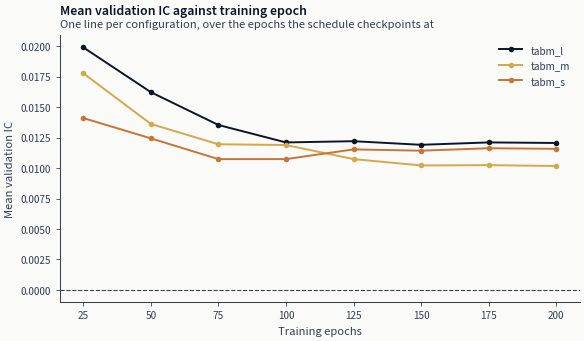

In [13]:
curves = scored.sort("config_name", "checkpoint_value")
config_names = curves.get_column("config_name").unique(maintain_order=True).to_list()
# `ml4t_palette` returns a list of that many colours, so it is called once and indexed.
palette = ml4t_palette(len(config_names), categorical=True)

fig, ax = plt.subplots(figsize=FIGSIZE["single"])
for index, config_name in enumerate(config_names):
    series = curves.filter(pl.col("config_name") == config_name)
    ax.plot(
        series.get_column("checkpoint_value"),
        series.get_column("ic_mean"),
        marker="o",
        markersize=4,
        lw=1.4,
        color=palette[index],
        label=config_name,
    )
zero_line(ax)
ax.set_xlabel("Training epochs")
ax.set_ylabel("Mean validation IC")
ax.legend(fontsize=8, frameon=False)
add_message_title(
    ax,
    "Mean validation IC against training epoch",
    subtitle="One line per configuration, over the epochs the schedule checkpoints at",
)
# The alt text counts rather than asserts: whether a curve turns over is the question the figure
# exists to answer, and a line described as peaking when it does not is a claim the data refutes.
_peaks = (
    curves.group_by("config_name")
    .agg(
        peak=pl.col("checkpoint_value").sort_by("ic_mean", descending=True).first(),
        first=pl.col("checkpoint_value").min(),
        last=pl.col("checkpoint_value").max(),
    )
    .with_columns(
        interior=pl.col("peak").is_between(pl.col("first"), pl.col("last"), closed="none")
    )
)
_n_interior = int(_peaks.get_column("interior").sum())
show_with_alt(
    fig,
    "A line chart of mean validation information coefficient against training epoch, one line per "
    "configuration, with a dashed line at zero. Counted from the underlying frame, "
    f"{_n_interior} of {_peaks.height} configurations reach their highest information coefficient "
    "at an epoch that is neither the first nor the last, which is what an interior optimum looks "
    "like on this chart.",
)

In [14]:
coverage_rows = []
for run in execution.runs:
    if not run.training.complete:
        raise RuntimeError(f"Incomplete training result: {run.training.hash}")
    for prediction in run.predictions:
        record = prediction.registry_record()
        coverage = prediction.coverage()
        if not prediction.complete or coverage is None or coverage["status"] != "complete":
            raise RuntimeError(f"Incomplete prediction result: {prediction.hash}")
        coverage_rows.append(
            {
                "config_name": run.training.spec()["config_name"],
                "checkpoint": record["checkpoint_value"],
                "training_hash": run.training.hash,
                "prediction_hash": prediction.hash,
                "coverage_status": coverage["status"],
                "expected_rows": coverage["n_expected"],
                "actual_rows": coverage["n_actual"],
                "training_artifacts": len(run.training.artifacts()),
                "prediction_artifacts": len(prediction.artifacts()),
            }
        )

coverage_table = pl.DataFrame(coverage_rows).sort("config_name", "checkpoint")
coverage_table

config_name,checkpoint,training_hash,prediction_hash,coverage_status,expected_rows,actual_rows,training_artifacts,prediction_artifacts
str,i64,str,str,str,i64,i64,i64,i64
"""tabm_l""",25,"""d33b6bf029c0""","""2972bde899c6""","""complete""",7170323,7170323,311,1
"""tabm_l""",50,"""d33b6bf029c0""","""e8c002946adf""","""complete""",7170323,7170323,311,1
"""tabm_l""",75,"""d33b6bf029c0""","""d651d5f24660""","""complete""",7170323,7170323,311,1
"""tabm_l""",100,"""d33b6bf029c0""","""1cd465c1a1ae""","""complete""",7170323,7170323,311,1
"""tabm_l""",125,"""d33b6bf029c0""","""9937ccb1c617""","""complete""",7170323,7170323,311,1
…,…,…,…,…,…,…,…,…
"""tabm_s""",100,"""e87301eac8b2""","""9b072b79fbb1""","""complete""",7170323,7170323,311,1
"""tabm_s""",125,"""e87301eac8b2""","""8cd6faf936a7""","""complete""",7170323,7170323,311,1
"""tabm_s""",150,"""e87301eac8b2""","""e110e12de412""","""complete""",7170323,7170323,311,1


In [15]:
execution_diagnostics = pl.DataFrame(execution.diagnostics)
execution_diagnostics

status,training_hash,execution_order,compatibility_group,compatibility_group_size,group_size,reused,base_fold_preparations,base_fold_preparation_s,candidate_fit_s,preparation_fraction,disk_fold_cache
str,str,str,str,i64,i64,bool,i64,f64,f64,f64,bool
"""completed""","""e87301eac8b2""","""fold_major""","""386ad902f18a""",3,3,true,0,0.0,0.0,0.0,false
"""completed""","""b48d09c1eca8""","""fold_major""","""386ad902f18a""",3,3,true,0,0.0,0.0,0.0,false
"""completed""","""d33b6bf029c0""","""fold_major""","""386ad902f18a""",3,3,true,0,0.0,0.0,0.0,false


## 6. Naming the sets the later notebooks open

`16_backtest` never opens the population. It opens **named prediction sets**, one per label and
family, because a comparison is only meaningful within one label's protocol.
`15_model_analysis` opens both - the population, to confirm the run filled every member it
promised, and the named sets, to make the comparison. Freezing is what creates those names.

Only an unnarrowed canonical run publishes them, and for the same reason a narrowed run may not
publish the canonical population: a name must not mean two different member sets at two different
times. A run that overrides a parameter, selects a subset, or runs on a device other than the
declared one keeps its rows and publishes no name.

<!-- ML4T_ZH_BEGIN c0025-p000 -->
## 6. 為後續 Notebook 開啟的集合命名

`16_backtest` 不會開啟模型群組，而是開啟每種標籤與模型類別各一組的**具名預測集合**，因為比較只有在單一標籤的相同流程內才有意義。`15_model_analysis` 會開啟兩者：透過模型群組確認本次執行完成承諾的每位成員，再透過具名集合進行比較。固定集合正是建立這些名稱的步驟。

只有未縮小範圍的標準執行會發布它們；理由與縮小範圍的執行不得發布標準模型群組相同：一個名稱不能在不同時間代表兩組不同成員。覆寫參數、選取子集，或在非宣告裝置上執行，都會保留各自資料列，但不發布標準名稱。
<!-- ML4T_ZH_END c0025-p000 -->


In [16]:
set_rows = []
if is_published_population:
    label_name = label.replace("_", "-")
    full_set_name = f"us-equities-{label_name}-tabular-dl-v1"
    full_set = study.predictions.freeze(
        execution.catalog_rows,
        name=full_set_name,
        supersedes=candidate_set_supersedes(
            study, name=full_set_name, declared=SUPERSEDES_SETS.get(full_set_name, "")
        ),
    )
    diagnostic_rows = execution.catalog_rows.filter(
        pl.col("config_name").is_in(DIAGNOSTIC_CONFIG_NAMES)
        # `.fill_null(True)` covers a family that publishes no checkpoint value at all, where the
        # comparison is null rather than false and would otherwise empty the frame.
        & (
            pl.col("checkpoint_value") == pl.col("checkpoint_value").max().over("config_name")
        ).fill_null(True)
    )
    diagnostic_set_name = f"us-equities-{label_name}-tabular-dl-diagnostics-v1"
    diagnostic_set = study.predictions.freeze(
        diagnostic_rows,
        name=diagnostic_set_name,
        supersedes=candidate_set_supersedes(
            study, name=diagnostic_set_name, declared=SUPERSEDES_SETS.get(diagnostic_set_name, "")
        ),
    )
    set_rows = [
        {
            "role": "backtest population",
            "set_name": full_set.name,
            "members": len(full_set.members),
        },
        {
            "role": "bounded diagnostics",
            "set_name": diagnostic_set.name,
            "members": len(diagnostic_set.members),
        },
    ]
compatible_sets = pl.DataFrame(
    set_rows,
    schema={"role": pl.String, "set_name": pl.String, "members": pl.Int64},
)
compatible_sets

role,set_name,members
str,str,i64
"""backtest population""","""us-equities-fwd-ret-1d-tabular…",24
"""bounded diagnostics""","""us-equities-fwd-ret-1d-tabular…",1


`15_model_analysis.py` reopens the named compatible and diagnostic sets. `16_backtest.py` passes
every full-set catalog row directly to the shared backtest runner. Model metrics do not choose a
configuration or checkpoint.

<!-- ML4T_ZH_BEGIN c0027-p000 -->
`15_model_analysis.py` 會重新開啟具名的相容集合與診斷集合。`16_backtest.py` 將完整集合目錄中的每列，直接傳給共用回測執行器。模型指標不決定設定或檢查點。
<!-- ML4T_ZH_END c0027-p000 -->


## What to notice

**A checkpoint is part of a configuration, not a detail of how it was fitted.** Saving weights
every 25 epochs turns three configurations into twenty-four scoreable models. Treating that as
three candidates while quietly keeping each one's best epoch would report the maximum of eight
numbers as though it were one, which is why every checkpoint is registered separately and
compared as its own candidate.

**A complete run is not the same as a scored one.** Cross-sectional information coefficient needs
a minimum number of names on a date before that date can be ranked at all. A universe whose
stocks do not overlap in time can satisfy every coverage check and still score zero dates,
leaving a null IC under a status that reads complete. The assertion above refuses that rather
than reporting it.

**This grid measures capacity and nothing finer.** Width and member count move together across
the three rungs, so a difference between them is a difference in capacity as a whole. Separating
the two would need a grid holding one fixed while the other varies, which this case study does
not declare.

**Known limitations.** The features are the same point-in-time columns the previous two
notebooks read, so anything absent from them is absent here too; the architecture finds
interactions among the columns it is given and does not create information. Validation results
say how the fits ranked on folds that have been read many times over by the time a case study
reaches this notebook, and say nothing about behaviour under a changed feature distribution.

**Next**: [`09_dl_nlinear`](09_dl_nlinear.ipynb) drops the flat-table representation and gives a
model the ordered window instead.

<!-- ML4T_ZH_BEGIN c0028-p000 -->
## 應觀察的重點

**檢查點是設定的一部分，不只是擬合過程的細節。** 每 25 個 epoch 儲存一次權重，會使三項設定產生二十四個可評分模型。若暗中保留各設定的最佳 epoch，卻只算三個候選者，就是將八個數字的最大值當作一個數字報告；因此各檢查點都分別登錄，並作為獨立候選者比較。

**完整執行不等於有評分結果。** 橫斷面資訊係數要求某日期至少有足夠股票，該日才可排序。若股票交易期間彼此不重疊，可能通過所有涵蓋率檢查，卻沒有任何可評分日期，使狀態顯示完整、資訊係數卻為空值。上方斷言會拒絕這種情況，而非照常報告。

**此網格只衡量整體容量，不辨別更細的原因。** 三級階梯的寬度與成員數同步變動，因此級間差異代表整體容量差異。若要區分兩者，須在網格中固定一項、只改變另一項；本案例研究並未宣告這種網格。

**已知限制。** 特徵與前兩份 Notebook 讀取的逐時點欄位相同，因此原本缺少的資訊，在此也同樣缺少；模型架構只能找出現有欄位之間的交互作用，不會創造資訊。驗證結果只說明模型在各折的排序表現；案例研究進行到此 Notebook 時，各折已被多次查看，結果也無法說明特徵分布改變時的行為。

**下一步**：[`09_dl_nlinear`](09_dl_nlinear.ipynb) 放棄平面表格表示法，改為提供模型按時間排序的窗口。
<!-- ML4T_ZH_END c0028-p000 -->
